# Análisis de sesgo — Deserción en educación superior (Colombia), IES × año

Cuantifica los sesgos del dataset `data/processed/dataset_ies.csv` (1.928 IES-año, 295 IES, 2015–2021) y prueba las
técnicas de mitigación que ofrece el repositorio como **opciones** (`src/modelado/`). Nada de lo que sigue cambia el
dataset ni los valores por defecto del pipeline; las cifras salen de los datos del repositorio.

Siete bloques: **a)** selección y cobertura, **b)** supervivencia, **c)** concentración geográfica, **d)** desbalance por
sector y carácter, **e)** faltantes no aleatorios, **f)** medición, **g)** fuga temporal. Al final, la sensibilidad al
umbral de denominador y una comparación de esquemas de validación y de pesos con un modelo lineal de referencia.

**Alcance.** Los contrastes de hipótesis son orientativos: las filas de una misma IES no son independientes.

In [1]:
# Configuración: rutas relativas a la raíz del proyecto y librerías
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)  # la configuración usa rutas relativas a la raíz del proyecto

from src.config import load_config
from src.modelado import sesgo as S
from src.modelado.geografia import agregar_geografia, denominador
from src.modelado.mitigacion import ESQUEMAS_PESOS, agregar_panel_incompleto, metricas_por_subgrupo, pesos_muestrales
from src.modelado.particion import (
    ETIQUETAS_CARACTER, ETIQUETAS_SECTOR, cargar_dataset, construir_preprocesador, particion_dejando_fuera,
    particion_group_kfold, particion_group_kfold_estratificado, particion_por_departamento, particion_temporal,
    preparar_x, variables_modelado_desde_config,
)
from src.transform.terridata import transformar_terridata

# Misma paleta que el EDA: azul = oficial, naranja = privada; gris para el resto
AZUL, NARANJA, GRIS, OSCURO = "#2a78d6", "#eb6834", "#8a8984", "#0d366b"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:.3f}")
pct = lambda v, _=None: f"{v:.0%}"

In [2]:
cfg = load_config(ROOT / "config" / "config.yaml")
assert cfg["unidad_analisis"] == "ies"
df = cargar_dataset(cfg)  # valores por defecto: ventana 2015-2021, SENA incluido, sin opciones de sesgo
ANIOS = (int(df["anio"].min()), int(df["anio"].max()))
cod = {"cod_divipola_mpio": str, "cod_ies": str, "sector": str, "caracter": str}
interim = ROOT / cfg["rutas"]["interim"]
exclusiones = pd.read_csv(ROOT / "reports" / "exclusiones_calidad.csv", dtype={"cod_ies": str}, encoding="utf-8-sig")
catalogo = pd.read_csv(interim / "snies_catalogo.csv", dtype={**cod, "cod_divipola_mpio_programa": str})

# Universo: toda IES-año con tasa anual en 2015-2021 antes de cualquier filtro, con el filtro que la saca (si alguno)
universo = S.universo_spadies(cfg)
universo = S.clasificar_exclusion(universo, exclusiones, df, cfg.get("min_matriculados_t2", 100))
universo = S.adjuntar_atributos(universo, catalogo)
universo["sector_et"] = universo["sector"].map(ETIQUETAS_SECTOR)
universo["caracter_et"] = universo["caracter"].map(ETIQUETAS_CARACTER)
dfg = agregar_geografia(df)
dfg["sector_et"] = dfg["sector"].map(ETIQUETAS_SECTOR)
dfg["caracter_et"] = dfg["caracter"].map(ETIQUETAS_CARACTER)

print(f"Dataset: {len(df):,} IES-año · {df['cod_ies'].nunique()} IES · {ANIOS[0]}–{ANIOS[1]}")
print(f"Universo antes de filtros: {len(universo):,} IES-año · {universo['cod_ies'].nunique()} IES")
display(universo["estado"].value_counts().rename("IES-año").to_frame())

Dataset: 1,928 IES-año · 295 IES · 2015–2021
Universo antes de filtros: 2,148 IES-año · 321 IES


,IES-año
estado,
incluida,1928
bajo denominador mínimo,97
régimen especial,77
inconsistencia de fuentes,37
posible cierre,9


## a) Sesgo de selección y cobertura

Los filtros de calidad (denominador mínimo, posible cierre, inconsistencia entre fuentes, régimen especial) cambian quién
está en el dataset. Se compara la composición en tres etapas y la tasa de lo que se sacó con la de lo que se quedó.

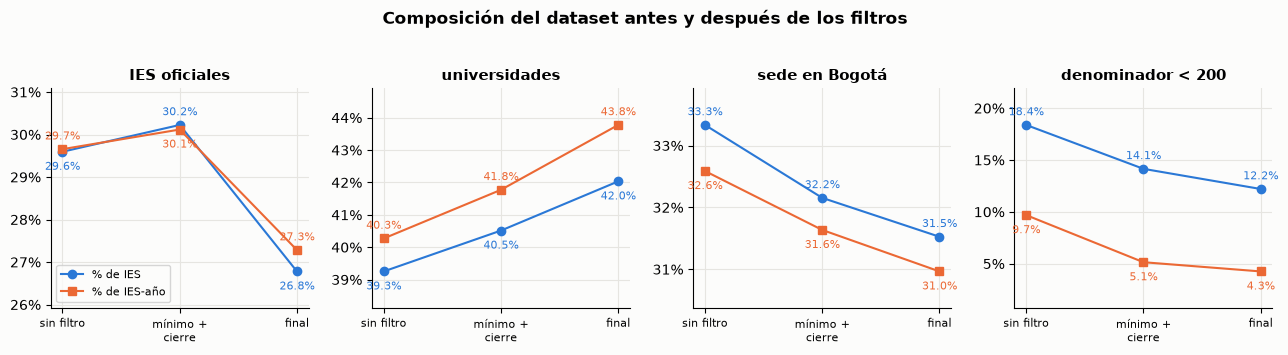

In [3]:
etapas = ["sin filtro", "tras mínimo y cierre", "dataset final"]
comp = {}
for col, valor, nombre in (("sector", "1", "IES oficiales"), ("caracter", "4", "universidades"), ("ciudad_principal", "Bogotá", "sede en Bogotá"),
                           ("tramo_tamano", "menos de 200", "denominador < 200")):
    t = S.cobertura_por_etapa(universo, col)
    comp[nombre] = t[t[col] == valor].set_index("etapa").reindex(etapas)[["pct_ies", "pct_filas"]]

fig, ejes = plt.subplots(1, 4, figsize=(13, 3.4), sharey=False)
for ax, (nombre, t) in zip(ejes, comp.items()):
    ax.plot(etapas, t["pct_ies"], marker="o", color=AZUL, label="% de IES")
    ax.plot(etapas, t["pct_filas"], marker="s", color=NARANJA, label="% de IES-año")
    for x, (a, b) in enumerate(zip(t["pct_ies"], t["pct_filas"])):
        arriba_ies = a >= b  # la etiqueta del valor más alto va arriba y la del más bajo, abajo, para que no se pisen
        ax.annotate(f"{a:.1%}", (x, a), xytext=(0, 7 if arriba_ies else -13), textcoords="offset points", ha="center", fontsize=8, color=AZUL)
        ax.annotate(f"{b:.1%}", (x, b), xytext=(0, -13 if arriba_ies else 7), textcoords="offset points", ha="center", fontsize=8, color=NARANJA)
    ax.set_title(nombre)
    ax.set_xticks(range(3), ["sin filtro", "mínimo +\ncierre", "final"], fontsize=8)
    ax.yaxis.set_major_formatter(pct)
    ax.margins(y=0.25)
ejes[0].legend(fontsize=8, loc="best")
fig.suptitle("Composición del dataset antes y después de los filtros", fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

,filas,ies,mediana,media,desv,p10,p90,P(tasa excluida > tasa incluida),p_valor
estado,,,,,,,,,
incluida,1928,295,0.099,0.120,0.087,0.053,0.203,NaN,NaN
bajo denominador mínimo,97,32,0.248,0.279,0.202,0.055,0.553,0.776,0.000
posible cierre,9,6,0.174,0.172,0.107,0.036,0.291,0.653,0.113
inconsistencia de fuentes,37,22,0.180,0.232,0.166,0.066,0.461,0.733,0.000
régimen especial,77,13,0.060,0.099,0.145,0.018,0.177,0.302,0.000


,grupo,filas,ies,mediana,media,desv,p10,p90
0,excluida · oficial,111,20,0.066,0.117,0.148,0.021,0.255
1,excluida · privada,109,40,0.257,0.291,0.191,0.097,0.557
2,incluida · oficial,526,79,0.087,0.106,0.065,0.049,0.191
3,incluida · privada,1402,216,0.102,0.126,0.093,0.056,0.207


Media de la tasa: universo 0.129 · dataset 0.120 · excluidas 0.203


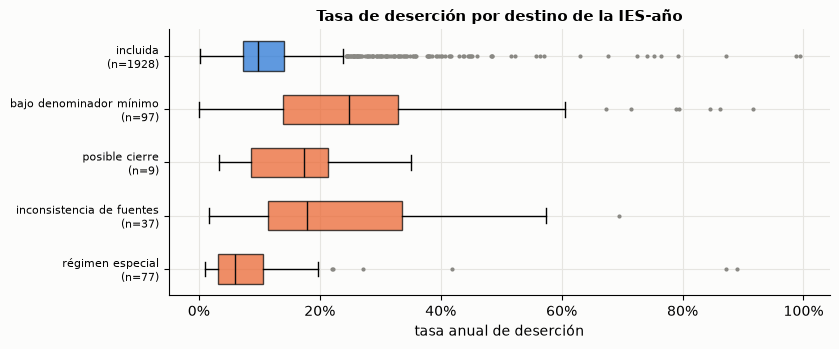

In [4]:
# Distribución de la tasa: IES-año que salen (por motivo) frente a las que se quedan
resumen = S.resumen_tasa(universo, "estado").set_index("estado").reindex(S.ETAPAS)
cont = {e: S.contraste(universo.loc[universo["estado"] == e, "tasa_desercion"], universo.loc[universo["estado"] == "incluida", "tasa_desercion"])
        for e in S.ETAPAS[1:]}
resumen["P(tasa excluida > tasa incluida)"] = [np.nan] + [cont[e]["prob_superioridad"] for e in S.ETAPAS[1:]]
resumen["p_valor"] = [np.nan] + [cont[e]["p_valor"] for e in S.ETAPAS[1:]]
display(resumen)

universo["sale"] = np.where(universo["estado"] == "incluida", "incluida", "excluida")
display(S.resumen_tasa(universo.assign(grupo=universo["sale"] + " · " + universo["sector_et"].fillna("sin catálogo")), "grupo"))
print(f"Media de la tasa: universo {universo['tasa_desercion'].mean():.3f} · dataset {df['tasa_desercion'].mean():.3f} · "
      f"excluidas {universo.loc[universo['sale'] == 'excluida', 'tasa_desercion'].mean():.3f}")

fig, ax = plt.subplots(figsize=(8.5, 3.6))
orden = S.ETAPAS
datos = [universo.loc[universo["estado"] == e, "tasa_desercion"] for e in orden]
bp = ax.boxplot(datos, orientation="horizontal", patch_artist=True, widths=0.55, showfliers=True, flierprops=dict(markersize=3, markerfacecolor=GRIS, markeredgecolor="none"))
for caja, e in zip(bp["boxes"], orden):
    caja.set(facecolor=AZUL if e == "incluida" else NARANJA, alpha=0.75, edgecolor="#0b0b0b")
for m in bp["medians"]:
    m.set(color="#0b0b0b")
ax.set_yticks(range(1, len(orden) + 1), [f"{e}\n(n={len(d)})" for e, d in zip(orden, datos)], fontsize=8)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(pct)
ax.set(title="Tasa de deserción por destino de la IES-año", xlabel="tasa anual de deserción")
plt.tight_layout()
plt.show()

In [5]:
# Cobertura por departamento sede: IES antes de los filtros, IES en el dataset final y lo que se pierde
from src.homologation.divipola import cargar_divipola
divipola = cargar_divipola(ROOT / cfg["rutas"]["raw"] / "dane" / "divipola.csv")
nombres_depto = divipola.drop_duplicates("cod_depto").set_index("cod_depto")["depto_norm"].str.title()
ies_u = universo.drop_duplicates("cod_ies").assign(depto=lambda d: d["cod_depto"].map(nombres_depto))
ies_f = universo[universo["estado"] == "incluida"].drop_duplicates("cod_ies")
dep = pd.DataFrame({"ies_sin_filtro": ies_u.groupby("depto").size(), "ies_final": ies_f.assign(depto=ies_f["cod_depto"].map(nombres_depto)).groupby("depto").size()}).fillna(0).astype(int)
dep["pct_ies_sin_filtro"] = dep["ies_sin_filtro"] / dep["ies_sin_filtro"].sum()
dep["pct_ies_final"] = dep["ies_final"] / dep["ies_final"].sum()
dep["cambio_pp"] = (dep["pct_ies_final"] - dep["pct_ies_sin_filtro"]) * 100
dep = dep.sort_values("ies_sin_filtro", ascending=False)
display(dep.head(10))
print(f"{len(dep)} departamentos con IES antes de los filtros; {int((dep['ies_final'] > 0).sum())} después; "
      f"{int((dep['ies_final'] < 3).sum())} tienen menos de 3 IES en el dataset final.")
perd = dep.assign(perdidas=dep["ies_sin_filtro"] - dep["ies_final"]).sort_values("perdidas", ascending=False)
display(perd.head(6)[["ies_sin_filtro", "ies_final", "perdidas", "cambio_pp"]])

,ies_sin_filtro,ies_final,pct_ies_sin_filtro,pct_ies_final,cambio_pp
depto,,,,,
"Bogota, D.C.",107,93,0.333,0.315,-1.808
Antioquia,49,48,0.153,0.163,1.006
Valle Del Cauca,32,30,0.100,0.102,0.201
Santander,18,18,0.056,0.061,0.494
Atlantico,17,16,0.053,0.054,0.128
Bolivar,13,12,0.040,0.041,0.018
Cundinamarca,9,5,0.028,0.017,-1.109
Risaralda,7,7,0.022,0.024,0.192
Boyaca,7,7,0.022,0.024,0.192


27 departamentos con IES antes de los filtros; 27 después; 8 tienen menos de 3 IES en el dataset final.


,ies_sin_filtro,ies_final,perdidas,cambio_pp
depto,,,,
"Bogota, D.C.",107,93,14,-1.808
Cundinamarca,9,5,4,-1.109
Valle Del Cauca,32,30,2,0.201
Antioquia,49,48,1,1.006
Atlantico,17,16,1,0.128
Bolivar,13,12,1,0.018


## b) Sesgo de supervivencia y panel incompleto

Una IES que deja de reportar (o aparece tarde, o tiene huecos) tiene menos años. Se cuenta cuántas IES no cubren los 7 años
y cómo se compara su tasa con la de las IES de panel completo.

Panel completo (7 años): 256 de 295 IES en el dataset (86.8%); antes de los filtros eran 291 de 321 (90.7%).


,IES
patron,
completo,256
sale antes,16
intermitente,10
entra tarde,9
entra tarde y sale antes,4


,grupo,filas,ies,mediana,media,desv,p10,p90,patron
0,panel completo,1792,256,0.096,0.113,0.067,0.052,0.185,NaN
1,panel incompleto,136,39,0.162,0.223,0.194,0.069,0.456,NaN
2,NaN,27,9,0.144,0.185,0.172,0.091,0.223,entra tarde
3,NaN,8,4,0.277,0.279,0.143,0.136,0.441,entra tarde y sale antes
4,NaN,45,10,0.167,0.200,0.117,0.084,0.384,intermitente
5,NaN,56,16,0.145,0.253,0.249,0.063,0.653,sale antes


Menos de 7 años -> tasa mediana 0.162 frente a 0.096 en panel completo


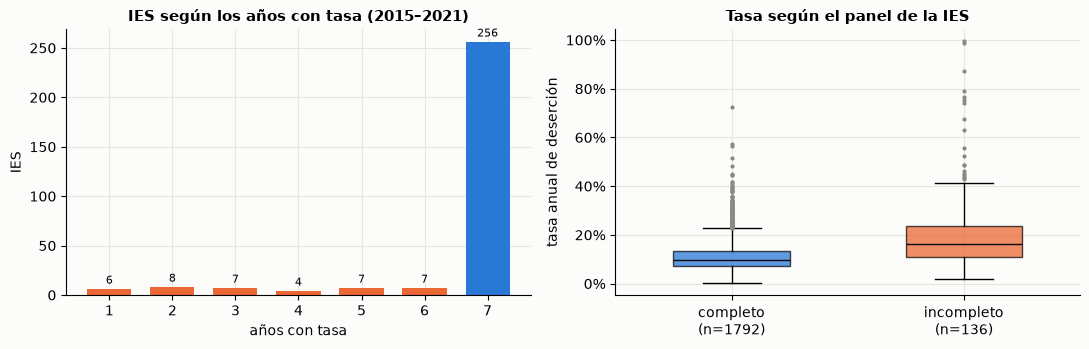

In [6]:
pan = S.patron_panel(df, ANIOS)
panel_universo = S.patron_panel(universo, ANIOS)
print(f"Panel completo ({ANIOS[1] - ANIOS[0] + 1} años): {int(pan['panel_completo'].sum())} de {len(pan)} IES en el dataset "
      f"({pan['panel_completo'].mean():.1%}); antes de los filtros eran {int(panel_universo['panel_completo'].sum())} de {len(panel_universo)} "
      f"({panel_universo['panel_completo'].mean():.1%}).")
display(pan["patron"].value_counts().rename("IES").to_frame())
display(S.comparar_panel(df, ANIOS))
mas = S.comparar_panel(df, ANIOS).iloc[:2].set_index("grupo")
print("Menos de 7 años -> tasa mediana", f"{mas.loc['panel incompleto', 'mediana']:.3f}", "frente a", f"{mas.loc['panel completo', 'mediana']:.3f}", "en panel completo")

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1]})
n = pan["n"].value_counts().reindex(range(1, 8), fill_value=0)
barras = ejes[0].bar(n.index, n.values, color=[AZUL if i == 7 else NARANJA for i in n.index], width=0.7)
ejes[0].bar_label(barras, fontsize=8, padding=2)
ejes[0].set(title="IES según los años con tasa (2015–2021)", xlabel="años con tasa", ylabel="IES")
tmp = df.merge(pan[["cod_ies", "panel_completo"]], on="cod_ies")
cajas = [tmp.loc[tmp["panel_completo"], "tasa_desercion"], tmp.loc[~tmp["panel_completo"], "tasa_desercion"]]
bp = ejes[1].boxplot(cajas, patch_artist=True, widths=0.5, tick_labels=[f"completo\n(n={len(cajas[0])})", f"incompleto\n(n={len(cajas[1])})"],
                     flierprops=dict(markersize=3, markerfacecolor=GRIS, markeredgecolor="none"))
for caja, c in zip(bp["boxes"], (AZUL, NARANJA)):
    caja.set(facecolor=c, alpha=0.75, edgecolor="#0b0b0b")
for m in bp["medians"]:
    m.set(color="#0b0b0b")
ejes[1].yaxis.set_major_formatter(pct)
ejes[1].set(title="Tasa según el panel de la IES", ylabel="tasa anual de deserción")
plt.tight_layout()
plt.show()

## c) Concentración geográfica

Cada IES se asigna al municipio donde tiene más programas. Bogotá, Medellín y Cali concentran la oferta y, con ella, las
filas. Además, todas las IES de un municipio comparten sus variables territoriales: tres municipios aportan solo 21 valores
distintos por variable (3 municipios × 7 años).

,ciudad_principal,filas,ies,pct_filas,pct_ies
0,Bogotá,597,93,0.310,0.315
1,Medellín,208,30,0.108,0.102
2,Cali,139,22,0.072,0.075
3,Resto del país,984,150,0.510,0.508


Bogotá + Medellín + Cali: 49.2% de las IES y 49.0% de las IES-año.


,region,filas,ies,pct_filas,pct_ies
1,Andina,737,111,0.382,0.376
2,Bogotá D.C.,597,93,0.310,0.315
3,Caribe,289,43,0.150,0.146
5,Pacífica,272,43,0.141,0.146
4,Orinoquía,19,3,0.010,0.010
0,Amazonía,14,2,0.007,0.007


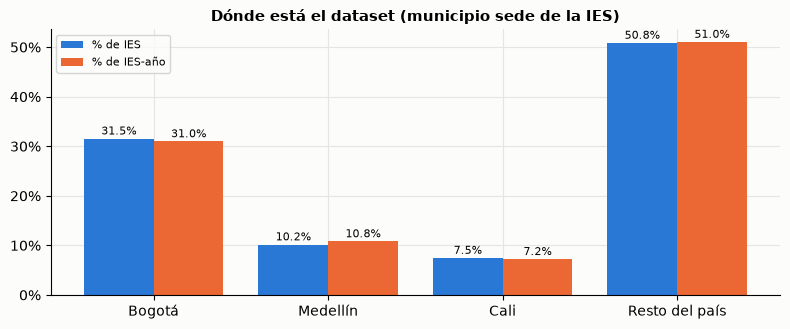

In [7]:
conc = S.concentracion_ciudades(df)
display(conc)
print(f"Bogotá + Medellín + Cali: {conc.iloc[:3]['pct_ies'].sum():.1%} de las IES y {conc.iloc[:3]['pct_filas'].sum():.1%} de las IES-año.")
reg = S.distribucion(dfg, "region").sort_values("filas", ascending=False)
display(reg)

fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(conc))
ax.bar(x - 0.2, conc["pct_ies"], 0.4, color=AZUL, label="% de IES")
ax.bar(x + 0.2, conc["pct_filas"], 0.4, color=NARANJA, label="% de IES-año")
for i, (a, b) in enumerate(zip(conc["pct_ies"], conc["pct_filas"])):
    ax.annotate(f"{a:.1%}", (i - 0.2, a), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8)
    ax.annotate(f"{b:.1%}", (i + 0.2, b), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8)
ax.set_xticks(x, conc["ciudad_principal"])
ax.yaxis.set_major_formatter(pct)
ax.set(title="Dónde está el dataset (municipio sede de la IES)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [8]:
# Variación de las variables territoriales dentro de las tres ciudades frente al resto del país
territoriales = [c for c in df.columns if c.startswith("td_") and c != "td_poblacion_total_t1"] + [
    "punt_global_media_t1", "pct_estrato_bajo_t1", "n_estudiantes_t1", "mpio_matriculados_t2", "mpio_ies_con_oferta_t2"]
disp = S.dispersion_territorial(df, territoriales)
print(f"Municipios distintos: {disp.attrs['municipios_ciudades']} en las tres ciudades y {disp.attrs['municipios_resto']} en el resto del país.")
display(disp.sort_values("razon_desv").reset_index(drop=True))
print("razón < 1: la variable varía menos dentro de las tres ciudades que en el resto; > 1: varía más (variables de tamaño y de escala).")

# Correlación de la tasa con las variables territoriales, con y sin las tres ciudades
ciudad = dfg["ciudad_principal"] != "Resto del país"
filas = []
for c in territoriales:
    filas.append({"variable": c, "rho_todo": dfg[[c, "tasa_desercion"]].corr("spearman").iloc[0, 1],
                  "rho_sin_ciudades": dfg.loc[~ciudad, [c, "tasa_desercion"]].corr("spearman").iloc[0, 1],
                  "rho_solo_ciudades": dfg.loc[ciudad, [c, "tasa_desercion"]].corr("spearman").iloc[0, 1]})
tc = pd.DataFrame(filas).set_index("variable")
tc["cambio"] = tc["rho_sin_ciudades"] - tc["rho_todo"]
display(tc.reindex(tc["cambio"].abs().sort_values(ascending=False).index).head(10))

Municipios distintos: 3 en las tres ciudades y 64 en el resto del país.


,variable,desv_ciudades,desv_resto,razon_desv,valores_distintos_ciudades,valores_distintos_resto
0,td_pct_poblacion_rural_t1,0.723,11.949,0.061,20,420
1,td_miseria_pct_t1,0.786,6.181,0.127,6,113
2,pct_estrato_bajo_t1,0.025,0.153,0.162,15,305
3,td_nbi_pct_t1,3.046,13.309,0.229,6,121
4,td_idf_ahorro_t1,4.265,10.003,0.426,21,405
5,td_mdm_gestion_t1,4.349,10.138,0.429,15,284
6,td_idf_t1,1.729,3.934,0.439,21,365
7,td_pct_pob_15_19_t1,0.432,0.939,0.460,21,391
8,td_idf_transferencias_t1,6.789,14.523,0.467,21,407
9,td_idf_deuda_t1,2.861,5.857,0.489,20,333


razón < 1: la variable varía menos dentro de las tres ciudades que en el resto; > 1: varía más (variables de tamaño y de escala).


,rho_todo,rho_sin_ciudades,rho_solo_ciudades,cambio
variable,,,,
punt_global_media_t1,0.014,-0.170,0.134,-0.184
mpio_matriculados_t2,0.085,-0.085,0.062,-0.170
td_ipm_censo_t1,0.008,0.178,-0.052,0.169
td_miseria_pct_t1,0.008,0.173,-0.052,0.164
td_nbi_pct_t1,-0.005,0.159,-0.052,0.164
mpio_ies_con_oferta_t2,0.107,-0.039,0.104,-0.146
n_estudiantes_t1,0.105,-0.027,0.108,-0.132
pct_estrato_bajo_t1,-0.028,0.087,-0.059,0.115
td_idf_inversion_t1,-0.116,-0.003,-0.170,0.114


## d) Desbalance por carácter y sector

IES-año por sector y carácter:


caracter_et,institución universitaria,tecnológica,técnica profesional,universidad,All
sector_et,,,,,
oficial,119,42,52,313,526
privada,615,176,80,531,1402
All,734,218,132,844,1928


IES por sector y carácter:


caracter_et,institución universitaria,tecnológica,técnica profesional,universidad,All
sector_et,,,,,
oficial,17,6,8,48,79
privada,93,31,16,76,216
All,110,37,24,124,295


,sector_et,caracter_et,filas,ies,mediana,media,desv
0,oficial,institución universitaria,119,17,0.106,0.112,0.048
1,oficial,tecnológica,42,6,0.137,0.142,0.057
2,oficial,técnica profesional,52,8,0.206,0.221,0.091
3,oficial,universidad,313,48,0.074,0.080,0.038
4,privada,institución universitaria,615,93,0.112,0.120,0.068
5,privada,tecnológica,176,31,0.181,0.219,0.148
6,privada,técnica profesional,80,16,0.206,0.250,0.127
7,privada,universidad,531,76,0.082,0.083,0.031


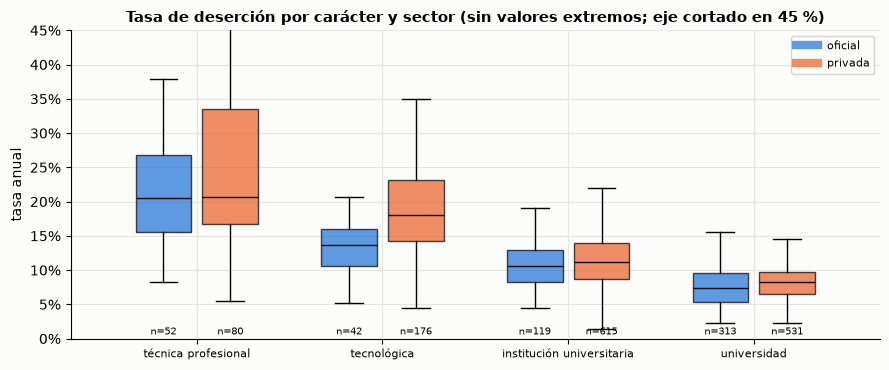

In [9]:
cruce = pd.crosstab(dfg["sector_et"], dfg["caracter_et"], margins=True)
ies_cruce = pd.crosstab(dfg.drop_duplicates("cod_ies")["sector_et"], dfg.drop_duplicates("cod_ies")["caracter_et"], margins=True)
print("IES-año por sector y carácter:"); display(cruce)
print("IES por sector y carácter:"); display(ies_cruce)
display(S.resumen_tasa(dfg, ["sector_et", "caracter_et"]) if False else dfg.groupby(["sector_et", "caracter_et"])["tasa_desercion"].agg(
    filas="size", ies=lambda s: dfg.loc[s.index, "cod_ies"].nunique(), mediana="median", media="mean", desv="std").reset_index())

fig, ax = plt.subplots(figsize=(9, 3.8))
orden_car = list(ETIQUETAS_CARACTER.values())
for k, (sec, color) in enumerate((("oficial", AZUL), ("privada", NARANJA))):
    datos = [dfg.loc[(dfg["sector_et"] == sec) & (dfg["caracter_et"] == c), "tasa_desercion"] for c in orden_car]
    pos = np.arange(len(orden_car)) + (k - 0.5) * 0.36
    bp = ax.boxplot(datos, positions=pos, widths=0.3, patch_artist=True, showfliers=False)
    for caja in bp["boxes"]:
        caja.set(facecolor=color, alpha=0.75, edgecolor="#0b0b0b")
    for m in bp["medians"]:
        m.set(color="#0b0b0b")
    for p, d in zip(pos, datos):
        ax.annotate(f"n={len(d)}", (p, 0), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=7)
    ax.plot([], [], color=color, lw=6, alpha=0.75, label=sec)
ax.set_xticks(range(len(orden_car)), orden_car, fontsize=8)
ax.yaxis.set_major_formatter(pct)
ax.set(title="Tasa de deserción por carácter y sector (sin valores extremos; eje cortado en 45 %)", ylabel="tasa anual", ylim=(0, 0.45))
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## e) Faltantes no aleatorios

Los nulos de las explicativas vienen por **bloques de años** (MDM y SNIES en 2015–2016, Saber 11 en 2019 y 2021). Se mide
cuánto cambia ese patrón por subgrupo y si, fuera de los bloques, la falta depende del sector, el carácter o el territorio.

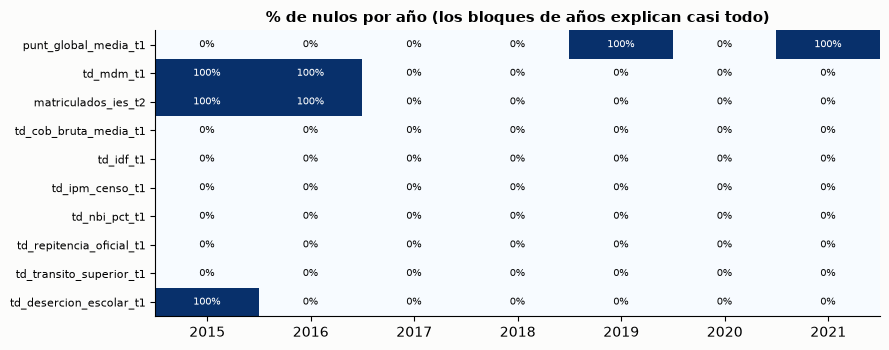

Falta fuera de los bloques de años (solo años en que la variable existe):


,grupo,variable,filas_con_año_observable,pct_nulos_fuera_de_bloques,pct_nulos_max_subgrupo,subgrupo_max,p_valor
16,caracter,td_nbi_pct_t1,1928,0.002,0.023,1,0.000
15,caracter,td_ipm_censo_t1,1928,0.002,0.023,1,0.000
17,caracter,td_repitencia_oficial_t1,1928,0.004,0.023,1,0.000
18,caracter,td_transito_superior_t1,1928,0.002,0.023,1,0.000
14,caracter,td_idf_t1,1928,0.002,0.023,1,0.000
13,caracter,td_cob_bruta_media_t1,1928,0.004,0.023,1,0.000
11,caracter,td_mdm_t1,1369,0.001,0.022,1,0.000
19,caracter,td_desercion_escolar_t1,1649,0.004,0.018,1,0.001
26,region,td_nbi_pct_t1,1928,0.002,0.010,Caribe,0.004
25,region,td_ipm_censo_t1,1928,0.002,0.010,Caribe,0.004


Variables sin ningún nulo fuera de los bloques: ['matriculados_ies_t2', 'punt_global_media_t1']


,falta_saber11,falta_mdm,falta_snies
sector_et,,,
oficial,0.283,0.297,0.293
privada,0.282,0.289,0.289


In [10]:
cols_nulos = ["punt_global_media_t1", "td_mdm_t1", "matriculados_ies_t2", "td_cob_bruta_media_t1", "td_idf_t1",
              "td_ipm_censo_t1", "td_nbi_pct_t1", "td_repitencia_oficial_t1", "td_transito_superior_t1", "td_desercion_escolar_t1"]
por_anio = dfg.groupby("anio")[cols_nulos].apply(lambda g: g.isna().mean())
fig, ax = plt.subplots(figsize=(9, 3.6))
im = ax.imshow(por_anio.T.values, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(por_anio)), por_anio.index)
ax.set_yticks(range(len(cols_nulos)), cols_nulos, fontsize=8)
ax.grid(False)
for i in range(por_anio.shape[1]):
    for j in range(por_anio.shape[0]):
        v = por_anio.iloc[j, i]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7, color="white" if v > 0.5 else "#0b0b0b")
ax.set_title("% de nulos por año (los bloques de años explican casi todo)")
plt.tight_layout()
plt.show()

filas = []
for grupo in ("sector", "caracter", "region", "ciudad_principal"):
    for c in cols_nulos:
        r = S.contraste_nulos(dfg, c, grupo)
        pg = S.nulos_por_grupo(dfg[dfg.groupby("anio")[c].transform(lambda s: s.notna().any())], [c], grupo)[c]
        filas.append({"grupo": grupo, "variable": c, "filas_con_año_observable": r["filas"], "pct_nulos_fuera_de_bloques": r["pct_nulos"],
                      "pct_nulos_max_subgrupo": pg.max(), "subgrupo_max": pg.idxmax(), "p_valor": r["p_valor"]})
nul = pd.DataFrame(filas)
print("Falta fuera de los bloques de años (solo años en que la variable existe):")
display(nul[nul["pct_nulos_fuera_de_bloques"] > 0].sort_values("pct_nulos_max_subgrupo", ascending=False).head(12))
print("Variables sin ningún nulo fuera de los bloques:", sorted(set(nul[nul["pct_nulos_fuera_de_bloques"] == 0]["variable"])))
bloques = dfg.groupby(["sector_et"])[["falta_saber11", "falta_mdm", "falta_snies"]].mean()
display(bloques)

## f) Sesgo de medición

La tasa es `desertores / matriculados de hace dos semestres`: con denominadores chicos es muy inestable, y la matrícula de
SPADIES no siempre coincide con la de SNIES (`ratio_spadies_snies`).

,tramo_tamano,filas,ies,mediana,desv,iqr,desv_binomial_ref,razon,pct_sobre_50
0,menos de 200,82,36,0.142,0.195,0.101,0.034,5.818,0.085
1,200–499,208,58,0.160,0.122,0.104,0.021,5.719,0.024
2,500–999,194,63,0.146,0.111,0.123,0.014,7.789,0.015
3,1.000–4.999,765,138,0.096,0.053,0.053,0.006,8.526,0.000
4,5.000 o más,679,110,0.087,0.042,0.044,0.003,14.639,0.000


Spearman entre la tasa y el tamaño (denominador): -0.355


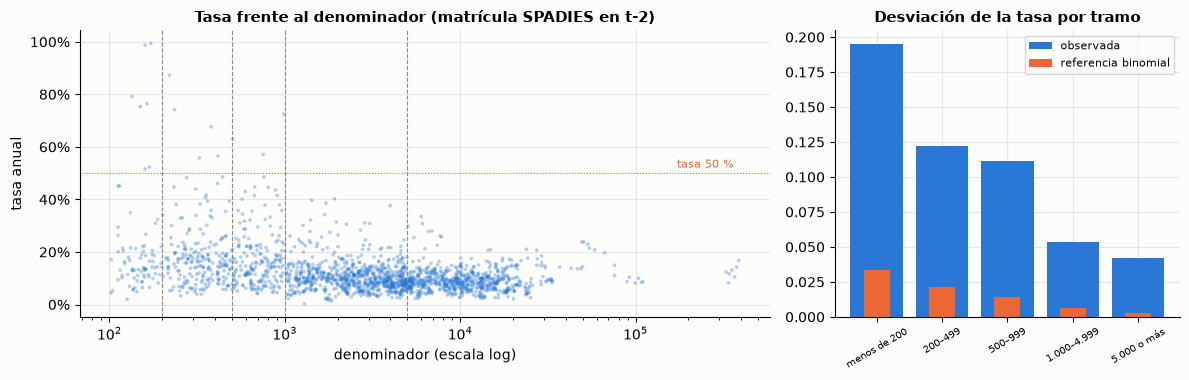

Inconsistencia SPADIES/SNIES (exclusiones_calidad.csv y cola del ratio en el dataset):


,grupo,filas,mediana_tasa
0,ratio > umbral,10,0.296
1,ratio < 1/umbral,8,0.143
2,SNIES sin dato dentro de su cobertura,19,0.180
3,"en el dataset, ratio > 2.0 o < 0.50 (cerca del...",31,0.152


{'count': 1369.0, 'mean': 0.897, 'std': 0.214, 'min': 0.354, '25%': 0.79, '50%': 0.882, '75%': 0.97, 'max': 2.628}


In [11]:
disp_t = S.dispersion_por_tamano(df)
display(disp_t)
rho = df[["tasa_desercion", "log_matriculados_spadies_t2"]].corr("spearman").iloc[0, 1]
print(f"Spearman entre la tasa y el tamaño (denominador): {rho:.3f}")

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw={"width_ratios": [2, 1]})
ejes[0].scatter(denominador(df), df["tasa_desercion"], s=7, alpha=0.35, color=AZUL, edgecolor="none")
ejes[0].set_xscale("log")
for corte in (200, 500, 1000, 5000):
    ejes[0].axvline(corte, color=GRIS, lw=0.8, ls="--")
ejes[0].axhline(0.5, color=NARANJA, lw=0.8, ls=":")
ejes[0].annotate("tasa 50 %", (denominador(df).max(), 0.5), xytext=(-4, 4), textcoords="offset points", ha="right", fontsize=8, color=NARANJA)
ejes[0].yaxis.set_major_formatter(pct)
ejes[0].set(title="Tasa frente al denominador (matrícula SPADIES en t-2)", xlabel="denominador (escala log)", ylabel="tasa anual")
ejes[1].bar(disp_t["tramo_tamano"].astype(str), disp_t["desv"], color=AZUL, label="observada")
ejes[1].bar(disp_t["tramo_tamano"].astype(str), disp_t["desv_binomial_ref"], color=NARANJA, width=0.4, label="referencia binomial")
ejes[1].tick_params(axis="x", labelrotation=30, labelsize=7)
ejes[1].legend(fontsize=8)
ejes[1].set(title="Desviación de la tasa por tramo")
plt.tight_layout()
plt.show()

print("Inconsistencia SPADIES/SNIES (exclusiones_calidad.csv y cola del ratio en el dataset):")
display(S.ratio_fuera_de_rango(exclusiones, df, cfg.get("umbral_ratio_inconsistencia", 3)))
print(df["ratio_spadies_snies"].describe().round(3).to_dict())

## g) Fuga temporal

Para cada explicativa se recalcula su valor desde la fuente con el rezago permitido (Saber 11 y TerriData en t-1, matrícula
SNIES en t-2, denominador de SPADIES de la propia fila) y se cuentan las filas que no coinciden. Una explicativa que usara un
año posterior tendría discrepancias. El test equivalente es `tests/test_sesgo.py`.

In [12]:
td = transformar_terridata(pd.read_csv(interim / "terridata_largo.csv", dtype=cod), cfg["anios"])
fuga = S.verificar_rezagos(
    df, pd.read_csv(interim / "saber11_municipio.csv", dtype=cod), pd.read_csv(interim / "snies_matricula_mpio.csv", dtype=cod),
    pd.read_csv(interim / "snies_matricula_programa.csv", dtype=cod), td, pd.read_csv(interim / "spadies.csv", dtype=cod),
    cfg.get("rezago_matricula", 2))
print(f"{len(fuga)} variables verificadas · {int(fuga['comparadas'].sum()):,} valores comparados · {int(fuga['discrepancias'].sum())} discrepancias")
display(fuga.groupby(["fuente", "rezago"], as_index=False).agg(variables=("columna", "size"), comparadas=("comparadas", "sum"), discrepancias=("discrepancias", "sum")))
from src.modelado.particion import columnas_explicativas
print("Explicativas por defecto sin sufijo de rezago:", S.explicativas_sin_rezago(columnas_explicativas(df)))
# TerriData arrastra la población hacia atrás (bfill): ¿alguna celda que usa el dataset sale de un año posterior?
largo_td = pd.read_csv(interim / "terridata_largo.csv", dtype=cod)
display(S.celdas_rellenadas_hacia_atras(largo_td, cfg["anios"], df))

32 variables verificadas · 55,813 valores comparados · 0 discrepancias


,fuente,rezago,variables,comparadas,discrepancias
0,SNIES municipio,2,2,3856,0
1,SNIES programas,2,1,1369,0
2,"SPADIES (denominador, t-2)",2,1,1928,0
3,Saber 11,1,5,6915,0
4,TerriData,1,23,41745,0


Explicativas por defecto sin sufijo de rezago: []


,variable,celdas_usadas,nulas_hacia_adelante,rellenadas_con_anio_posterior
0,poblacion_total,448,3,0
1,pct_poblacion_rural,448,3,0
2,pct_pob_15_19,448,3,0
3,pct_pob_20_24,448,3,0


## Mitigación 1 — umbral de denominador

`min_matriculados_t2` es 100. Se reconstruye el dataset en memoria con 50 y 200 (sin escribir nada) para ver cuánto depende
la muestra del umbral. Con 100 debe reproducirse el dataset publicado.

In [13]:
sens = S.sensibilidad_umbral(cfg, (50, 100, 200))
display(sens)
publicado = sens.loc[sens["umbral"] == cfg.get("min_matriculados_t2", 100)].iloc[0]
assert int(publicado["filas"]) == len(df) and int(publicado["ies"]) == df["cod_ies"].nunique(), "la reconstrucción no reproduce el dataset"
print("Con el umbral publicado la reconstrucción coincide con el dataset.")

,umbral,filas,ies,pct_ies_oficiales,pct_filas_bogota,mediana,media,p95,desv,filas_sobre_50
0,50,1966,297,0.266,0.312,0.099,0.123,0.279,0.091,18
1,100,1928,295,0.268,0.310,0.099,0.120,0.261,0.087,15
2,200,1846,281,0.274,0.309,0.097,0.117,0.250,0.077,8


Con el umbral publicado la reconstrucción coincide con el dataset.


## Mitigación 2 — esquemas de validación, pesos y errores por subgrupo

Modelo lineal de referencia (Ridge, `alpha=10`, sin ajuste de hiperparámetros): **no es el modelo final**, solo muestra
qué cambia al usar cada utilidad. Las métricas son el error absoluto medio (MAE) sobre filas de prueba, sin ponderar.

,esquema,filas_prueba,mae_modelo,mae_mediana,mejora_vs_mediana
0,GroupKFold por IES,1928,0.042,0.050,0.162
1,GroupKFold estratificado (sector x carácter),1928,0.042,0.050,0.155
2,GroupKFold por departamento,1928,0.044,0.051,0.137
3,"Entrena fuera de Bogotá, prueba en Bogotá",597,0.055,0.067,0.179
4,Temporal 2015–2019 / 2020–2021,544,0.041,0.051,0.179


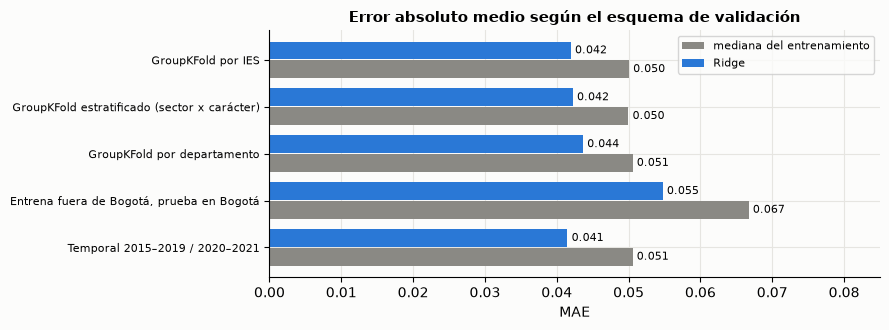

In [14]:
numericas, categoricas = variables_modelado_desde_config(df, cfg)
X = preparar_x(df, numericas, categoricas)
y = df["tasa_desercion"].to_numpy()


def modelo():
    return Pipeline([("pre", construir_preprocesador(numericas, categoricas)), ("ridge", Ridge(alpha=10.0))])


def evaluar(pliegues, pesos=None):
    """Predicciones fuera de muestra (índices de prueba) con el modelo y con la mediana del entrenamiento."""
    idx, pred, base = [], [], []
    for entrena, prueba in pliegues:
        m = modelo()
        if pesos is None:
            m.fit(X.iloc[entrena], y[entrena])
        else:
            m.fit(X.iloc[entrena], y[entrena], ridge__sample_weight=pesos[entrena])
        idx.append(prueba); pred.append(m.predict(X.iloc[prueba])); base.append(np.full(len(prueba), np.median(y[entrena])))
    idx = np.concatenate(idx)
    return idx, np.concatenate(pred), np.concatenate(base)


esquemas = {
    "GroupKFold por IES": list(particion_group_kfold(df, 5)),
    "GroupKFold estratificado (sector x carácter)": list(particion_group_kfold_estratificado(df, 5)),
    "GroupKFold por departamento": list(particion_por_departamento(df, 5)),
    "Entrena fuera de Bogotá, prueba en Bogotá": [particion_dejando_fuera(df, ("11",))],
    "Temporal 2015–2019 / 2020–2021": [particion_temporal(df, 2019)],
}
filas = []
resultados = {}
for nombre, pliegues in esquemas.items():
    idx, pred, base = evaluar(pliegues)
    resultados[nombre] = (idx, pred)
    filas.append({"esquema": nombre, "filas_prueba": len(idx), "mae_modelo": np.abs(pred - y[idx]).mean(), "mae_mediana": np.abs(base - y[idx]).mean()})
comp_esq = pd.DataFrame(filas)
comp_esq["mejora_vs_mediana"] = 1 - comp_esq["mae_modelo"] / comp_esq["mae_mediana"]
display(comp_esq)

fig, ax = plt.subplots(figsize=(9, 3.4))
y_pos = np.arange(len(comp_esq))
ax.barh(y_pos + 0.2, comp_esq["mae_mediana"], 0.38, color=GRIS, label="mediana del entrenamiento")
ax.barh(y_pos - 0.2, comp_esq["mae_modelo"], 0.38, color=AZUL, label="Ridge")
for i, (a, b) in enumerate(zip(comp_esq["mae_modelo"], comp_esq["mae_mediana"])):
    ax.annotate(f"{a:.3f}", (a, i - 0.2), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)
    ax.annotate(f"{b:.3f}", (b, i + 0.2), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)
ax.set_yticks(y_pos, comp_esq["esquema"], fontsize=8)
ax.invert_yaxis()
ax.legend(fontsize=8, loc="upper right")
ax.set(title="Error absoluto medio según el esquema de validación", xlabel="MAE", xlim=(0, 0.085))
plt.tight_layout()
plt.show()

ninguno  matriculados  raiz_matriculados  inverso_grupo  inverso_ies
variable         grupo                                                                                          
total            todas                        0.042         0.043              0.041          0.046        0.045
sector           oficial                      0.036         0.035              0.034          0.040        0.038
                 privada                      0.044         0.046              0.043          0.048        0.047
caracter         institución universitaria    0.041         0.042              0.041          0.045        0.045
                 tecnológica                  0.080         0.088              0.077          0.080        0.081
                 técnica profesional          0.082         0.082              0.081          0.082        0.087
                 universidad                  0.027         0.026              0.025          0.032        0.029
region           Amazonía                     0.049         0.037              0.043          0.043        0.045
                 Andina                       0.034         0.033              0.031          0.038        0.037
                 Bogotá D.C.                  0.054         0.056              0.054          0.057        0.056
                 Caribe                       0.045         0.047              0.045          0.049        0.047
                 Orinoquía                    0.022         0.021              0.019          0.029        0.026
                 Pacífica                     0.036         0.038              0.035          0.039        0.041
ciudad_principal Bogotá                       0.054         0.056              0.054          0.057        0.056
                 Cali                         0.039         0.040              0.039          0.039        0.047
                 Medellín                     0.030         0.032              0.029          0.036        0.033
                 Resto del país               0.037         0.037              0.035          0.042        0.041
tramo_tamano     menos de 200                 0.106         0.106              0.102          0.114        0.113
                 200–499                      0.064         0.071              0.062          0.067        0.068
                 500–999                      0.058         0.067              0.060          0.061        0.060
                 1.000–4.999                  0.038         0.036              0.036          0.041        0.042
                 5.000 o más                  0.027         0.027              0.026          0.032        0.029

,variable,grupo,filas,ies,mae,rmse,sesgo_medio
0,total,todas,1928,295,0.042,0.071,-0.001
1,sector,oficial,526,79,0.036,0.050,-0.002
2,sector,privada,1402,216,0.044,0.078,-0.001
3,caracter,institución universitaria,734,110,0.041,0.066,-0.001
4,caracter,tecnológica,218,37,0.080,0.136,-0.002
5,caracter,técnica profesional,132,24,0.082,0.110,-0.011
6,caracter,universidad,844,124,0.027,0.035,0.000
7,region,Amazonía,14,2,0.049,0.057,-0.005
8,region,Andina,737,111,0.034,0.052,-0.000
9,region,Bogotá D.C.,597,93,0.054,0.096,-0.001


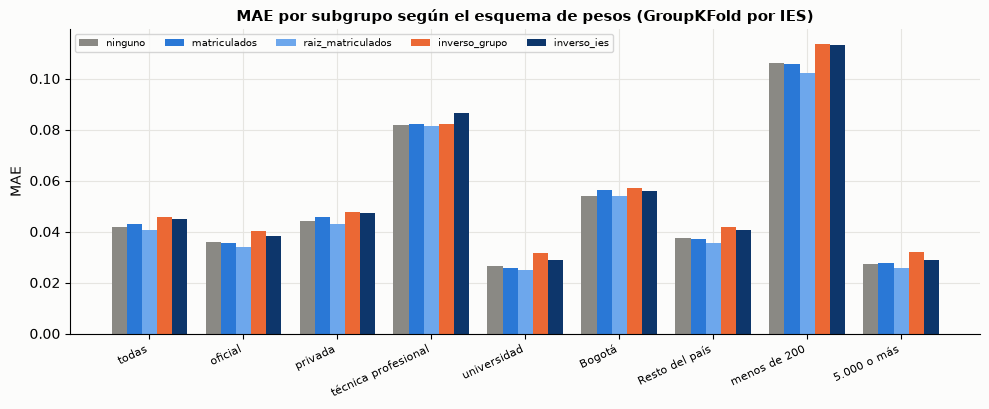

In [15]:
# Efecto de los pesos muestrales (GroupKFold por IES): MAE total y por subgrupo, sin ponderar
base_kf = esquemas["GroupKFold por IES"]
tablas = {}
for esquema in ESQUEMAS_PESOS:
    w = pesos_muestrales(df, esquema)
    idx, pred, _ = evaluar(base_kf, w)
    sub = metricas_por_subgrupo(df.iloc[idx], y[idx], pred, columnas=("sector", "caracter", "region", "ciudad_principal", "tramo_tamano"))
    tablas[esquema] = sub.set_index(["variable", "grupo"])["mae"]
mae_sub = pd.DataFrame(tablas)
display(mae_sub)

# Sesgo medio (predicho - observado) por subgrupo sin pesos
idx, pred, _ = evaluar(base_kf)
sub0 = metricas_por_subgrupo(df.iloc[idx], y[idx], pred, columnas=("sector", "caracter", "region", "ciudad_principal", "tramo_tamano"))
display(sub0)

fig, ax = plt.subplots(figsize=(10, 4.2))
quiere = [("total", "todas"), ("sector", "oficial"), ("sector", "privada"), ("caracter", "técnica profesional"), ("caracter", "universidad"),
          ("ciudad_principal", "Bogotá"), ("ciudad_principal", "Resto del país"), ("tramo_tamano", "menos de 200"), ("tramo_tamano", "5.000 o más")]
quiere = [q for q in quiere if q in mae_sub.index]
ancho = 0.16
colores = [GRIS, AZUL, "#6da7ec", NARANJA, OSCURO]
for k, esquema in enumerate(ESQUEMAS_PESOS):
    ax.bar(np.arange(len(quiere)) + (k - 2) * ancho, [mae_sub.loc[q, esquema] for q in quiere], ancho, color=colores[k], label=esquema)
ax.set_xticks(range(len(quiere)), [f"{g}" for _, g in quiere], rotation=25, ha="right", fontsize=8)
ax.legend(fontsize=7, ncol=5, loc="upper left")
ax.set(title="MAE por subgrupo según el esquema de pesos (GroupKFold por IES)", ylabel="MAE")
plt.tight_layout()
plt.show()

In [16]:
# MAE por subgrupo en la validación que deja fuera a Bogotá y en la temporal
for nombre in ("Entrena fuera de Bogotá, prueba en Bogotá", "Temporal 2015–2019 / 2020–2021"):
    idx, pred = resultados[nombre]
    print(nombre)
    display(metricas_por_subgrupo(df.iloc[idx], y[idx], pred, columnas=("sector", "caracter", "region")))

Entrena fuera de Bogotá, prueba en Bogotá


,variable,grupo,filas,ies,mae,rmse,sesgo_medio
0,total,todas,597,93,0.055,0.097,-0.012
1,sector,oficial,63,9,0.043,0.064,-0.014
2,sector,privada,534,84,0.056,0.101,-0.012
3,caracter,institución universitaria,261,39,0.051,0.079,0.005
4,caracter,tecnológica,82,15,0.105,0.190,-0.057
5,caracter,técnica profesional,44,9,0.078,0.111,-0.030
6,caracter,universidad,210,30,0.035,0.050,-0.011
7,region,Bogotá D.C.,597,93,0.055,0.097,-0.012


Temporal 2015–2019 / 2020–2021


,variable,grupo,filas,ies,mae,rmse,sesgo_medio
0,total,todas,544,276,0.041,0.074,-0.005
1,sector,oficial,147,74,0.035,0.045,0.007
2,sector,privada,397,202,0.044,0.083,-0.010
3,caracter,institución universitaria,213,108,0.041,0.069,-0.007
4,caracter,tecnológica,57,29,0.077,0.144,-0.005
5,caracter,técnica profesional,38,20,0.081,0.120,-0.006
6,caracter,universidad,236,119,0.027,0.034,-0.004
7,region,Amazonía,4,2,0.041,0.044,-0.001
8,region,Andina,209,105,0.032,0.055,0.001
9,region,Bogotá D.C.,167,85,0.054,0.101,-0.006


## Conclusiones

### Bias and limitations

*Borrador para adaptar al artículo; los números son los de este informe.*

**Selección.** El dataset cubre 295 de las 321 IES con tasa anual de SPADIES en 2015–2021 (1.928 de 2.148 IES-año). Las filas excluidas por denominador pequeño, inconsistencia entre fuentes o posible cierre tienen tasas más altas (mediana 14,8 % frente a 9,9 %); las privadas excluidas, en particular, tienen mediana de 25,7 % frente a 10,2 %. Los resultados describen a las IES con al menos 100 matriculados de referencia y datos consistentes; no se extienden a las instituciones pequeñas ni a las escuelas militares y policiales. Subir el umbral a 200 deja la mediana en 9,7 % y baja las tasas por encima de 50 % de 15 a 8.

**Supervivencia.** El 13 % de las IES (39 de 295) no tiene los siete años, y su tasa es más alta (mediana de 16,2 % frente a 9,6 %). El panel completo sobrerrepresenta a las instituciones que siguen reportando.

**Concentración geográfica.** La mitad de las IES (49 %) está en Bogotá, Medellín y Cali, y las variables territoriales casi no varían entre las IES de una misma ciudad (tres municipios aportan unos 20 valores por variable). Las correlaciones territoriales cambian de tamaño y de signo al quitar esas ciudades, así que los efectos territoriales no deben leerse como generales; Orinoquía y Amazonía tienen cinco IES en total.

**Desbalance.** Hay 79 IES oficiales y 216 privadas, y solo 24 técnicas profesionales y 37 tecnológicas, justo los grupos con tasas más altas (mediana de 13,7 % a 20,6 %) y más dispersas. En ellos, y en las IES con menos de 200 matriculados, el error es mayor (MAE de 0,08 a 0,11 frente a 0,03 en universidades), y el modelo subestima la deserción de las IES pequeñas. Se reporta el error por subgrupo, y los pesos muestrales no lo corrigen.

**Faltantes y medición.** Los datos faltan por bloques de años (MDM y SNIES en 2015–2016, Saber 11 en 2019 y 2021), de la misma forma en oficiales y privadas; casi no falta nada fuera de los bloques. La variación de la tasa cae con el tamaño de la IES y es mucho mayor que la que produciría el ruido de un denominador pequeño: la tasa no es un ruido binomial sino heterogénea entre instituciones.

**Fuga temporal.** Se recalcularon las 32 explicativas desde sus fuentes con los rezagos permitidos (contexto en t-1, matrícula en t-2): 0 discrepancias en 55.813 valores. Quedan limitaciones que esa verificación no cubre: los atributos institucionales (sector, carácter, sede) se toman de los programas de 2015–2021, y la selección por posible cierre usa información posterior a cada fila. Además, el censo 2018 (NBI/IPM) se usa solo desde el año objetivo 2020, por la fecha de publicación del DANE.

**Poder predictivo.** Un modelo lineal de referencia mejora entre 14 % y 18 % el error de predecir la mediana, con cualquiera de los cinco esquemas de validación (por IES, estratificado, por departamento, sin Bogotá y temporal). Las explicativas disponibles (contexto territorial y tamaño) explican poco de la variación entre instituciones.

### Bias and limitations (English version)

*Draft for the paper; figures are those of this report.*

**Selection.** The dataset covers 295 of the 321 institutions (IES) with an annual SPADIES dropout rate in 2015–2021 (1,928 of 2,148 institution-years). The rows removed for a small denominator, inconsistent sources or a probable closure have higher rates (median 14.8% vs. 9.9%); the excluded private institutions in particular have a median of 25.7% vs. 10.2% for the retained ones. The results therefore describe institutions with at least 100 enrolled students of reference and consistent records; they do not extend to very small institutions or to military and police academies. Raising the minimum denominator to 200 leaves the median at 9.7% and lowers the number of rates above 50% from 15 to 8.

**Survival.** 13% of the institutions (39 of 295) do not have all seven years, and their rate is higher (median 16.2% vs. 9.6%). The complete panel over-represents institutions that keep reporting.

**Geographic concentration.** Half of the institutions (49%) are in Bogotá, Medellín and Cali, and territorial variables hardly vary among institutions of the same city (three municipalities provide about 20 distinct values per variable). Territorial correlations change in size and sign when those cities are removed, so territorial effects should not be read as general; Orinoquía and Amazonía have only five institutions in total.

**Imbalance.** There are 79 public and 216 private institutions, and only 24 technical-professional and 37 technological ones, precisely the groups with the highest (median 13.7% to 20.6%) and most dispersed rates. In them, and in institutions with fewer than 200 enrolled students, the error is larger (MAE 0.08 to 0.11 vs. 0.03 for universities), and the model underestimates dropout in small institutions. We report error by subgroup; sample weights do not correct it.

**Missing data and measurement.** Missing values come in year blocks (MDM and SNIES in 2015–2016, Saber 11 in 2019 and 2021), identically for public and private institutions; almost nothing is missing outside those blocks. The dispersion of the rate falls with institution size and is far larger than a small denominator alone would produce: the rate is not binomial noise but real heterogeneity across institutions.

**Temporal leakage.** We recomputed the 32 explanatory variables from their sources using the allowed lags (context at t-1, enrollment at t-2): 0 discrepancies in 55,813 values. Limitations remain that this check does not cover: institutional attributes (sector, character, seat) come from the 2015–2021 programs, and the probable-closure selection uses information posterior to each row. In addition, the 2018 census indicators (NBI, multidimensional poverty) are used only from target year 2020 on, because DANE published the municipal multidimensional poverty measure on 31 January 2020 (the first NBI publication date could not be verified; it was revised in February 2021).

**Predictive power.** A reference linear model improves the error of predicting the median by 14% to 18% under all five validation schemes (by institution, stratified, by department, leaving Bogotá out, and temporal). The available explanatory variables (territorial context and size) explain little of the variation across institutions.